# Part 5: Leverage Effects (GJR-GARCH and EGARCH)

### Ramith Vaid | NTU Singapore

The symmetric GARCH(1,1) treats a 3% fall and a 3% rise as equally informative about tomorrow's volatility. In equities, falls usually raise volatility more than rises (the leverage effect). This part adds two asymmetric models and compares them with the symmetric one:

- **GJR-GARCH(1,1):** `sigma2_t = omega + (alpha + gamma * 1[r_{t-1} < 0]) * r_{t-1}^2 + beta * sigma2_{t-1}`. A positive `gamma` means negative returns raise volatility more.
- **EGARCH(1,1):** `ln sigma2_t = omega + beta * ln sigma2_{t-1} + alpha * (|z_{t-1}| - E|z|) + gamma * z_{t-1}`, with `z = r / sigma`. A negative `gamma` means negative returns raise volatility more.

Both are fit by maximum likelihood in `garch_utils.py` like the symmetric model, with normal innovations so the comparison changes only the variance equation. EGARCH's multi-day variance forecast uses the exact expectation of the exponentiated shocks (checked against a Monte Carlo simulation), not just the expectation of the log variance.

**Three comparisons.**
1. *Is there leverage in the data?* Descriptive statistics for the ten Part 4 assets, then full-sample fits: log-likelihood, AIC, BIC, a likelihood-ratio test of `gamma = 0` for GJR (under normal and under Student-t innovations, since fat tails can make a normal-likelihood test look stronger than it is).
2. *Does it help out of sample?* For JPM, the S&P 500, Apple, gold and Bitcoin, over the last 750 days with a complete 21-day forward window (the same scored days as Part 4's three blocks), all models refit daily on the trailing 750 returns: 21-day volatility forecast error against the corrected forward target, and the 1-day-ahead normal log score and 95%/99% VaR coverage.
3. *What does the asymmetry look like?* News impact curves from the full-sample fits.

The data end date is pinned to 2026-10-13.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import chi2, norm
import warnings
warnings.filterwarnings('ignore')

from garch_utils import (
    fit_garch_fast, garch_neg_log_likelihood, fit_garch_t, garch_t_neg_log_likelihood,
    fit_gjr, gjr_neg_log_likelihood, fit_gjr_t, gjr_t_neg_log_likelihood,
    fit_egarch, egarch_neg_log_likelihood, gjr_term_structure, egarch_term_structure, sigma2_next_gjr,
    egarch_logvar_path, gjr_variance_path, news_impact,
    prepare_vol_data, eval_positions, rolling_garch_term_structure, score_forecasts, dm_test,
    log_density_normal, kupiec_pof, garch_neg_log_likelihood_fast
)
import garch_utils as gu
print('Libraries loaded.')

Libraries loaded.


## 1. Data (same ten assets as Part 4)

In [2]:
UNIVERSE = {
    'JPM': 'US equity', '^GSPC': 'US equity index', 'AAPL': 'US equity', 'XOM': 'US equity',
    'EEM': 'International equity ETF', 'VNQ': 'REIT ETF', 'GLD': 'Commodity ETF', 'TLT': 'Bond ETF',
    'EURUSD=X': 'FX', 'BTC-USD': 'Crypto',
}
START, END = '2014-01-01', '2026-10-14'  # END is exclusive: last row is 2026-10-13
close = {tk: yf.download(tk, start=START, end=END, progress=False)['Close'].squeeze().dropna() for tk in UNIVERSE}
rets = {tk: np.log(c / c.shift(1)).dropna() for tk, c in close.items()}
print({tk: len(r) for tk, r in rets.items()})

{'JPM': 3213, '^GSPC': 3213, 'AAPL': 3213, 'XOM': 3213, 'EEM': 3213, 'VNQ': 3213, 'GLD': 3213, 'TLT': 3213, 'EURUSD=X': 3326, 'BTC-USD': 4409}


## 2. Is there a leverage effect in the data?

Two plain statistics per asset: the average absolute return on the day after a negative-return day against the day after a positive-return day, and the correlation between today's return and tomorrow's absolute return (negative values are the leverage signature: falls today go with large moves tomorrow).

In [3]:
rows = []
for tk, r in rets.items():
    x = r.values
    nxt = np.abs(x[1:]) * 100
    prev = x[:-1]
    rows.append({'ticker': tk, 'class': UNIVERSE[tk],
                 'mean |r| after down day (%)': nxt[prev < 0].mean(), 'mean |r| after up day (%)': nxt[prev > 0].mean(),
                 'ratio down/up': nxt[prev < 0].mean() / nxt[prev > 0].mean(),
                 'corr(r_t, |r_t+1|)': np.corrcoef(prev, nxt)[0, 1]})
leverage_desc = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 220)
print(leverage_desc.to_string(index=False))

  ticker                    class  mean |r| after down day (%)  mean |r| after up day (%)  ratio down/up  corr(r_t, |r_t+1|)
     JPM                US equity                        1.193                      1.039          1.149              -0.077
   ^GSPC          US equity index                        0.810                      0.626          1.293              -0.119
    AAPL                US equity                        1.335                      1.136          1.174              -0.085
     XOM                US equity                        1.215                      1.150          1.057              -0.036
     EEM International equity ETF                        0.976                      0.907          1.076              -0.065
     VNQ                 REIT ETF                        0.905                      0.777          1.165              -0.080
     GLD            Commodity ETF                        0.708                      0.740          0.957              -0.001


## 3. Full-sample fits

Maximum likelihood on each asset's full history (returns in percent). AIC = 2k - 2 log L and BIC = k ln(n) - 2 log L, with k = 3 for GARCH and 4 for GJR and EGARCH. The likelihood-ratio statistic for GJR against GARCH has one degree of freedom (`gamma = 0`); the same test is repeated with Student-t innovations (GARCH-t against GJR-t). EGARCH is not nested in either, so it is compared on AIC and BIC only.

In [4]:
fit_rows = []
full_params = {}
for tk, r in rets.items():
    x = r.values * 100
    n = len(x)
    pg = fit_garch_fast(x); ll_g = -garch_neg_log_likelihood(pg, x)
    pj = fit_gjr(x);        ll_j = -gjr_neg_log_likelihood(pj, x)
    pe = fit_egarch(x);     ll_e = -egarch_neg_log_likelihood(pe, x)
    pgt = fit_garch_t(x, start=tuple(pg)); ll_gt = -garch_t_neg_log_likelihood(pgt, x)
    pjt = fit_gjr_t(x, start=pj);          ll_jt = -gjr_t_neg_log_likelihood(pjt, x)
    full_params[tk] = {'garch': pg, 'gjr': pj, 'egarch': pe, 'x': x}
    lr = 2 * (ll_j - ll_g); lr_t = 2 * (ll_jt - ll_gt)
    fit_rows.append({
        'ticker': tk, 'n': n,
        'logL_garch': ll_g, 'logL_gjr': ll_j, 'logL_egarch': ll_e,
        'AIC_garch': 6 - 2 * ll_g, 'AIC_gjr': 8 - 2 * ll_j, 'AIC_egarch': 8 - 2 * ll_e,
        'BIC_garch': 3 * np.log(n) - 2 * ll_g, 'BIC_gjr': 4 * np.log(n) - 2 * ll_j, 'BIC_egarch': 4 * np.log(n) - 2 * ll_e,
        'gjr_gamma': pj[2], 'gjr_alpha': pj[1], 'gjr_beta': pj[3], 'LR_gjr_vs_garch': lr, 'LR_p': chi2.sf(max(lr, 0), 1),
        'egarch_gamma': pe[2], 'egarch_alpha': pe[1], 'egarch_beta': pe[3],
        'tLR_gjr_vs_garch': lr_t, 'tLR_p': chi2.sf(max(lr_t, 0), 1), 'gjr_t_gamma': pjt[2], 'gjr_t_nu': pjt[4], 'garch_t_nu': pgt[3]})
fits = pd.DataFrame(fit_rows)
fits['dAIC_gjr'] = fits['AIC_gjr'] - fits['AIC_garch']
fits['dAIC_egarch'] = fits['AIC_egarch'] - fits['AIC_garch']
fits['best_AIC'] = fits[['AIC_garch', 'AIC_gjr', 'AIC_egarch']].idxmin(axis=1).str.replace('AIC_', '')
fits['best_BIC'] = fits[['BIC_garch', 'BIC_gjr', 'BIC_egarch']].idxmin(axis=1).str.replace('BIC_', '')
print(fits[['ticker', 'logL_garch', 'logL_gjr', 'logL_egarch', 'dAIC_gjr', 'dAIC_egarch', 'best_AIC', 'best_BIC']].to_string(index=False))
print()
print(fits[['ticker', 'gjr_gamma', 'LR_gjr_vs_garch', 'LR_p', 'egarch_gamma', 'gjr_t_gamma', 'tLR_gjr_vs_garch', 'tLR_p', 'gjr_t_nu']].to_string(index=False))

  ticker  logL_garch    logL_gjr  logL_egarch  dAIC_gjr  dAIC_egarch best_AIC best_BIC
     JPM  -5,728.548  -5,697.273   -5,685.192   -60.551      -84.713   egarch   egarch
   ^GSPC  -4,089.771  -4,027.403   -4,013.082  -122.736     -151.379   egarch   egarch
    AAPL  -6,126.092  -6,080.870   -6,069.928   -88.445     -110.328   egarch   egarch
     XOM  -5,722.713  -5,719.446   -5,710.074    -4.533      -23.278   egarch   egarch
     EEM  -5,059.161  -5,038.292   -5,036.325   -39.737      -43.672   egarch   egarch
     VNQ  -4,641.766  -4,621.317   -4,622.925   -38.898      -35.681      gjr      gjr
     GLD  -4,332.546  -4,321.445   -4,328.681   -20.202       -5.730      gjr      gjr
     TLT  -3,976.386  -3,976.036   -3,975.538     1.301        0.305    garch    garch
EURUSD=X  -2,092.995  -2,091.710   -2,092.962    -0.570        1.935      gjr    garch
 BTC-USD -11,330.448 -11,320.282  -11,318.914   -18.332      -21.069   egarch   egarch

  ticker  gjr_gamma  LR_gjr_vs_garch  LR_p

## 4. News impact curves

Next-day variance as a function of today's return, with yesterday's conditional variance held at its full-sample average, for the symmetric, GJR and EGARCH fits on JPM and the S&P 500. The symmetric curve is a parabola around zero; asymmetry shows as the left arm lying above the right arm.

In [5]:
shocks = np.linspace(-6, 6, 241)
curves = {}
for tk in ['JPM', '^GSPC']:
    p = full_params[tk]
    x = p['x']
    s2bar = np.mean(gu._garch_filter(*p['garch'], x))
    curves[tk] = {m: news_impact(shocks, m, p[m], s2bar) for m in ('garch', 'gjr', 'egarch')}
    ratio = {m: float(news_impact([-3.0], m, p[m], s2bar)[0] / news_impact([3.0], m, p[m], s2bar)[0]) for m in ('garch', 'gjr', 'egarch')}
    print(f'{tk}: next-day variance after a -3% day vs. a +3% day: ' + ', '.join(f'{m} {v:.2f}x' for m, v in ratio.items()))

JPM: next-day variance after a -3% day vs. a +3% day: garch 1.00x, gjr 1.48x, egarch 1.46x
^GSPC: next-day variance after a -3% day vs. a +3% day: garch 1.00x, gjr 2.67x, egarch 2.57x


## 5. Out-of-sample: 21-day volatility, 1-day density and VaR

For each of the last 750 days with a complete 21-day forward window, each model is refit on the 750 returns ending that day. The 21-day forecast is the average expected variance over the next 21 days from the model's term structure, scored against the realized volatility of those days (the corrected target from Part 4). The 1-day forecast is the next day's variance, scored by the normal log density of the next day's return and by VaR breaches at 95% and 99% (normal quantiles). This refits three models on each of 750 days for each of five assets and takes a while.

In [6]:
OOS = ['JPM', '^GSPC', 'AAPL', 'GLD', 'BTC-USD']
models = {
    'garch': dict(fitter=fit_garch_fast, ts=None, nll=garch_neg_log_likelihood_fast),
    'gjr': dict(fitter=fit_gjr, ts=gjr_term_structure, nll=gjr_neg_log_likelihood),
    'egarch': dict(fitter=fit_egarch, ts=egarch_term_structure, nll=egarch_neg_log_likelihood),
}
oos = {}
failures = []
for tk in OOS:
    processed, ml = prepare_vol_data(close[tk])
    pos = eval_positions(len(processed), 750)
    dates = processed.index[pos]
    r_pct = processed['log_return'].values * 100
    frame = pd.DataFrame({'actual21': ml.loc[dates, 'target_vol'].values, 'r_next': r_pct[pos + 1]}, index=dates)
    for m, cfg in models.items():
        f = rolling_garch_term_structure(processed['log_return'], pos, 750, (1, 21), fitter=cfg['fitter'], term_structure=cfg['ts'], nll=cfg['nll'])
        failures.append({'ticker': tk, 'model': m, 'failed_fits': f.attrs['n_fit_failures']})
        frame[f'{m}_h21'] = f['h21'].values
        frame[f'{m}_sd1'] = f['h1'].values / np.sqrt(252)   # next-day sd in percent
        for k in range(f.shape[1] - 2):
            frame[f'{m}_p{k}'] = f[f'p{k}'].values
    oos[tk] = frame
    print(f'{tk}: {len(frame)} scored days, {dates[0].date()} to {dates[-1].date()}')
print('Failed fits (replaced by the previous day parameters):', {(d['ticker'], d['model']): d['failed_fits'] for d in failures if d['failed_fits']} or 'none')

JPM: 750 scored days, 2023-09-18 to 2026-09-14


^GSPC: 750 scored days, 2023-09-18 to 2026-09-14


AAPL: 750 scored days, 2023-09-18 to 2026-09-14


GLD: 750 scored days, 2023-09-18 to 2026-09-14


BTC-USD: 750 scored days, 2024-09-03 to 2026-09-22
Failed fits (replaced by the previous day parameters): none


In [7]:
rows21, rows1 = [], []
for tk, f in oos.items():
    base_loss = (f['garch_h21'] - f['actual21']) ** 2
    for m in models:
        s = score_forecasts(f['actual21'], f[f'{m}_h21'])
        row = {'ticker': tk, 'model': m, 'rmse21': s['rmse'], 'mae21': s['mae'], 'bias21': s['bias']}
        if m != 'garch':
            row['dm_vs_garch'], row['dm_p'] = dm_test((f[f'{m}_h21'] - f['actual21']) ** 2, base_loss, 20)
        rows21.append(row)
    ls = {m: log_density_normal(f['r_next'].values, f[f'{m}_sd1'].values ** 2) for m in models}
    for m in models:
        row = {'ticker': tk, 'model': m, 'mean_logscore': ls[m].mean()}
        if m != 'garch':
            d = ls[m] - ls['garch']
            row['score_diff_vs_garch'] = d.mean()
            row['score_t'] = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
        for level in (0.95, 0.99):
            thr = -norm.ppf(level) * f[f'{m}_sd1'].values
            x = int((f['r_next'].values < thr).sum())
            row[f'breaches_{int(level*100)}'] = x
            row[f'kupiec_p_{int(level*100)}'] = kupiec_pof(x, len(f), 1 - level)[1]
        rows1.append(row)
oos21 = pd.DataFrame(rows21)
oos1 = pd.DataFrame(rows1)
oos21['rmse_vs_garch'] = oos21['rmse21'] / oos21.groupby('ticker')['rmse21'].transform('first')
print('21-day average volatility forecast (annualized pp), 750 scored days; rmse_vs_garch < 1 means better than symmetric GARCH:')
print(oos21.to_string(index=False))
print()
print('1-day density and VaR (expected breaches: 37.5 at 95%, 7.5 at 99%):')
print(oos1.to_string(index=False))

21-day average volatility forecast (annualized pp), 750 scored days; rmse_vs_garch < 1 means better than symmetric GARCH:
 ticker  model  rmse21  mae21  bias21  dm_vs_garch  dm_p  rmse_vs_garch
    JPM  garch   8.363  6.202   1.153          NaN   NaN          1.000
    JPM    gjr   8.475  6.339   1.463        0.498 0.619          1.013
    JPM egarch   8.230  6.220   1.450       -0.283 0.777          0.984
  ^GSPC  garch   7.280  4.636   1.133          NaN   NaN          1.000
  ^GSPC    gjr   6.580  4.363   1.196       -1.702 0.089          0.904
  ^GSPC egarch   6.139  4.330   1.401       -1.293 0.197          0.843
   AAPL  garch  11.369  7.669   1.318          NaN   NaN          1.000
   AAPL    gjr  10.637  7.554   1.555       -1.335 0.182          0.936
   AAPL egarch  10.519  7.585   1.943       -1.098 0.273          0.925
    GLD  garch   8.794  5.647  -1.124          NaN   NaN          1.000
    GLD    gjr   8.318  5.348  -1.848       -1.092 0.275          0.946
    GLD egarch

### Does an asymmetric model change the fitted parameters over time?

The fitted asymmetry parameter averaged over the rolling refits, per asset.

In [8]:
rows = []
for tk, f in oos.items():
    rows.append({'ticker': tk, 'gjr_gamma_mean': f['gjr_p2'].mean(), 'gjr_gamma_min': f['gjr_p2'].min(), 'gjr_gamma_max': f['gjr_p2'].max(),
                 'egarch_gamma_mean': f['egarch_p2'].mean(), 'egarch_gamma_min': f['egarch_p2'].min(), 'egarch_gamma_max': f['egarch_p2'].max()})
gamma_roll = pd.DataFrame(rows)
print(gamma_roll.to_string(index=False))

 ticker  gjr_gamma_mean  gjr_gamma_min  gjr_gamma_max  egarch_gamma_mean  egarch_gamma_min  egarch_gamma_max
    JPM           0.172          0.054          0.329             -0.111            -0.188            -0.054
  ^GSPC           0.151          0.098          0.231             -0.156            -0.213            -0.112
   AAPL           0.119          0.057          0.502             -0.097            -0.160            -0.055
    GLD          -0.085         -0.168         -0.021              0.056             0.016             0.116
BTC-USD           0.070          0.009          0.137             -0.042            -0.098             0.010


## 6. Chart

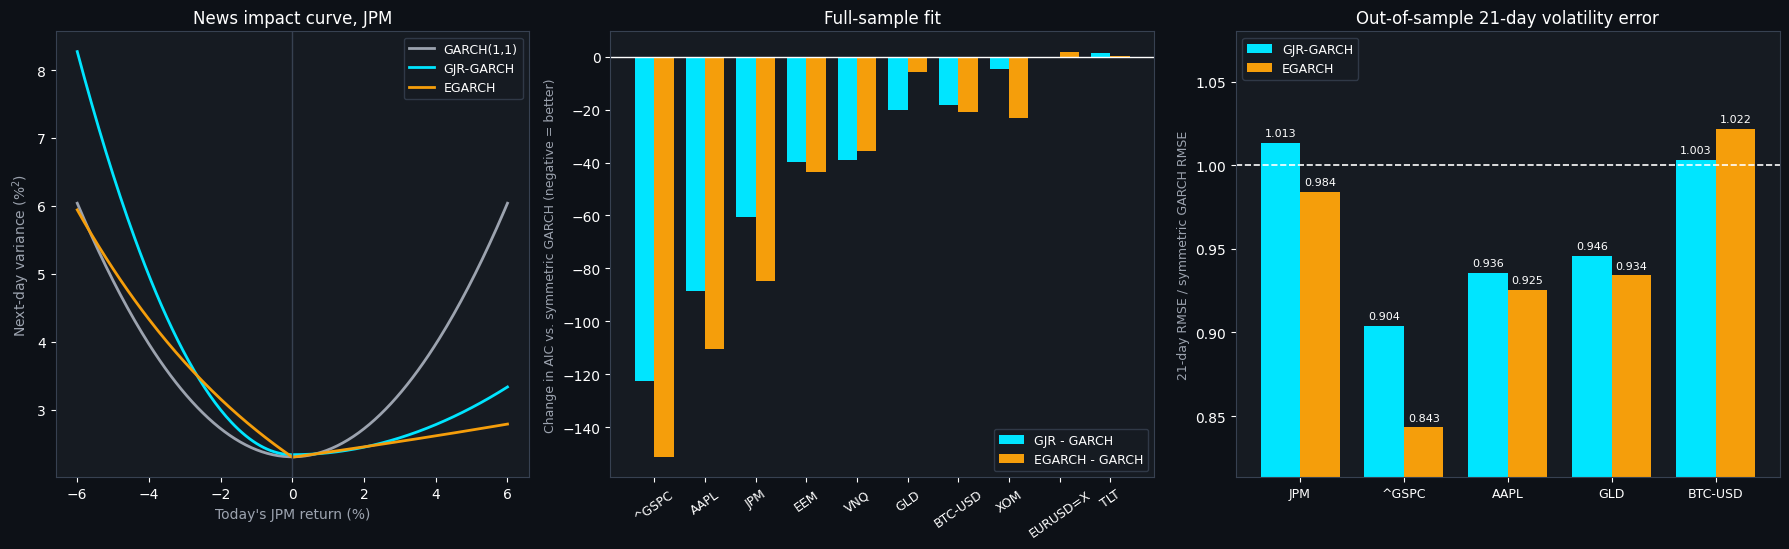

Saved chart_part5_leverage.png


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw={'width_ratios': [1, 1.15, 1.15]})
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
ax = axes[0]
c = curves['JPM']
for m, col, lab in (('garch', '#9ca3af', 'GARCH(1,1)'), ('gjr', '#00e5ff', 'GJR-GARCH'), ('egarch', '#f59e0b', 'EGARCH')):
    ax.plot(shocks, c[m], color=col, lw=2, label=lab)
ax.axvline(0, color='#374151', lw=1)
ax.set_xlabel("Today's JPM return (%)", color='#9ca3af')
ax.set_ylabel("Next-day variance (%$^2$)", color='#9ca3af')
ax.set_title('News impact curve, JPM', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)

ax = axes[1]
order = list(fits.sort_values('dAIC_gjr')['ticker'])
f_ = fits.set_index('ticker').loc[order]
x = np.arange(len(order))
w = 0.38
ax.bar(x - w/2, f_['dAIC_gjr'], w, color='#00e5ff', label='GJR - GARCH')
ax.bar(x + w/2, f_['dAIC_egarch'], w, color='#f59e0b', label='EGARCH - GARCH')
ax.axhline(0, color='white', lw=1)
ax.set_xticks(x)
ax.set_xticklabels(order, color='white', rotation=35, fontsize=9)
ax.set_ylabel('Change in AIC vs. symmetric GARCH (negative = better)', color='#9ca3af', fontsize=9)
ax.set_title('Full-sample fit', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)

ax = axes[2]
tk_order = OOS
x = np.arange(len(tk_order))
for off, m, col, lab in ((-w/2, 'gjr', '#00e5ff', 'GJR-GARCH'), (w/2, 'egarch', '#f59e0b', 'EGARCH')):
    vals = [oos21[(oos21.ticker == t) & (oos21.model == m)]['rmse_vs_garch'].iloc[0] for t in tk_order]
    bars = ax.bar(x + off, vals, w, color=col, label=lab)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.004, f'{v:.3f}', ha='center', fontsize=8, color='white')
ax.axhline(1, color='white', lw=1.2, ls='--')
ax.set_xticks(x)
ax.set_xticklabels(tk_order, color='white', fontsize=9)
ax.set_ylim(min(0.9, oos21['rmse_vs_garch'].min() - 0.03), max(oos21['rmse_vs_garch'].max() + 0.05, 1.08))
ax.set_ylabel('21-day RMSE / symmetric GARCH RMSE', color='#9ca3af', fontsize=9)
ax.set_title('Out-of-sample 21-day volatility error', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9, loc='upper left')
plt.tight_layout()
plt.savefig('chart_part5_leverage.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part5_leverage.png')

## 7. Summary and saved tables

In [10]:
leverage_desc.to_csv('part5_leverage_descriptive.csv', index=False)
fits.to_csv('part5_fit_comparison.csv', index=False)
oos21.to_csv('part5_oos_21day.csv', index=False)
oos1.to_csv('part5_oos_1day.csv', index=False)
gamma_roll.to_csv('part5_rolling_gamma.csv', index=False)
print('=' * 70)
print('PART 5 SUMMARY: LEVERAGE EFFECTS')
print('=' * 70)
print('Assets where GJR beats GARCH on AIC:', int((fits['dAIC_gjr'] < 0).sum()), 'of', len(fits),
      '; EGARCH:', int((fits['dAIC_egarch'] < 0).sum()), 'of', len(fits))
print('Assets with LR p < 0.05 (normal / Student-t):', int((fits['LR_p'] < 0.05).sum()), '/', int((fits['tLR_p'] < 0.05).sum()))
print()
print(oos21[['ticker', 'model', 'rmse21', 'rmse_vs_garch']].to_string(index=False))
print()
print('Files saved: chart_part5_leverage.png, part5_leverage_descriptive.csv, part5_fit_comparison.csv, part5_oos_21day.csv, part5_oos_1day.csv, part5_rolling_gamma.csv')

PART 5 SUMMARY: LEVERAGE EFFECTS
Assets where GJR beats GARCH on AIC: 9 of 10 ; EGARCH: 8 of 10
Assets with LR p < 0.05 (normal / Student-t): 8 / 7

 ticker  model  rmse21  rmse_vs_garch
    JPM  garch   8.363          1.000
    JPM    gjr   8.475          1.013
    JPM egarch   8.230          0.984
  ^GSPC  garch   7.280          1.000
  ^GSPC    gjr   6.580          0.904
  ^GSPC egarch   6.139          0.843
   AAPL  garch  11.369          1.000
   AAPL    gjr  10.637          0.936
   AAPL egarch  10.519          0.925
    GLD  garch   8.794          1.000
    GLD    gjr   8.318          0.946
    GLD egarch   8.215          0.934
BTC-USD  garch  13.228          1.000
BTC-USD    gjr  13.271          1.003
BTC-USD egarch  13.516          1.022

Files saved: chart_part5_leverage.png, part5_leverage_descriptive.csv, part5_fit_comparison.csv, part5_oos_21day.csv, part5_oos_1day.csv, part5_rolling_gamma.csv
